# Off-policy Monte Carlo: implementation

Off-policy Monte Carlo (MC) methods estimate the value of a target policy from episodes played by a different behavior policy. The notebook implements importance sampling (ordinary and weighted), the incremental weighted evaluation algorithm, off-policy control and importance sampling on truncated returns, reproduces the chapter's two importance-sampling examples (the second at reduced scale), and checks everything against exact dynamic programming (DP) or closed forms.
Ordinary importance sampling is unbiased, and when its mean is finite it converges almost surely; but with infinite variance it converges extremely slowly and its error has no usable scale, which the loop example shows (the book's wording, that it fails to converge, is looser).
Companion to the chapter note: [Off-policy Monte Carlo](../chapters/05b%20Off-policy%20Monte%20Carlo.md).

**Sections**
1. The importance-sampling ratio and the two estimators
2. Blackjack and its exact answer
3. Off-policy evaluation of one blackjack state
4. Infinite variance of ordinary importance sampling
5. Incremental evaluation with weighted importance sampling
6. Off-policy Monte Carlo control
7. Importance sampling on truncated returns
8. Checkpoints

**Not implemented:** the incremental form of ordinary importance sampling (it is the incremental average of the bandit chapter applied to scaled returns, so there is nothing new to code), control with a behavior policy that follows the current estimates (the behavior here is a fixed random policy), and the chapter's closing summary (it contains no algorithm).
Counts are scaled down from the book where a section says so; every deviation is stated in the section where it applies.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from collections.abc import Callable, Iterator

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_STATE, SEED_LOOP, SEED_EVAL, SEED_CONTROL, SEED_TRUNC = 1, 2, 3, 4, 5
STICK, HIT = 0, 1
BLACKJACK, DEALER_STAND, FIRST_DECISION, ACE_BONUS, TEN, BUST = 21, 17, 12, 10, 10, 22  # rule numbers; bust is coded as 22
N_SUMS, N_UP = 10, 10  # player sums 12 to 21 and dealer showing cards ace to ten
TINY = 1e-300  # guards divisions whose numerator is then zero
TWO_RETURNS, TWO_RATIOS = np.array([1.0, -1.0]), np.array([10.0, 0.5])  # the first demonstration of the two estimators
ONE_RETURN, ONE_RATIO = np.array([0.3]), np.array([7.0])  # and the single-return demonstration
CARD_VALUES = np.arange(1, 11)  # ace counts 1 or 11; every face card counts 10
P_CARD = np.array([1 / 13] * 9 + [4 / 13])  # infinite deck: the same probabilities on every draw
N_RANKS = 13  # card ranks of the infinite deck: ace, 2 to 10 and three face cards
SUMS = np.arange(FIRST_DECISION, BLACKJACK + 1)  # player sums with a decision to make
N_STATES = 200  # (sum, dealer card, usable ace)
TARGET_STICK = 20  # the target sticks on 20 or 21
P_HIT_TARGET = np.broadcast_to((SUMS < TARGET_STICK).astype(float)[:, None, None], (N_SUMS, N_UP, 2))
P_UNIFORM = 0.5
P_HIT_RANDOM = np.full((N_SUMS, N_UP, 2), P_UNIFORM)
START_HARD, START_DEALER = 3, 2  # the example state: an ace and a deuce (sum 13, usable ace) against a dealer deuce
BOOK_VALUE, BOOK_EPISODES = (
    -0.27726,
    100_000_000,
)  # the book's value of that state, and the on-policy episodes behind it
N_STATE_RUNS, N_STATE_EPISODES = 500, 10_000  # off-policy runs and episodes per run (the book: 100 runs)
N_ON_POLICY = 5_000_000  # on-policy episodes for the simulator check (the book: 10^8)
N_GRID = (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10_000)  # episode counts of the error table
EARLY_SET, Z_EARLY = (1, 2, 5, 10), 2.5  # fixed early episode counts; 2.5 is the two-sided 5% limit shared by 4 tests (Bonferroni)
N_VARIANCE_MIN = 1000  # smallest episode count at which the error is a mean of many returns
Z_LIMIT = 3  # standardized errors are measured in this many standard errors
AGREE_TOL = 1e-9  # two code paths computing the same quantity must agree to this
N_TRAJECTORIES = 21  # loop-task trajectories (1 to 21 steps) in the check that transition probabilities cancel
N_RANDOM, PARETO_SHAPE, P_NONZERO = 1000, 1.5, 0.3  # random returns and weights (a heavy-tailed share of them nonzero) for the incremental rule
P_STAY = 0.9  # one-state task: back returns to s with probability 0.9 and otherwise ends with reward 1
N_LOOP_RUNS, N_LOOP_EPISODES = 10, 1_000_000  # the book: ten runs of 10^8 episodes
LOOP_GRID = (10, 100, 1000, 10_000, 100_000, 1_000_000)  # episode counts of the running-estimate table
PLOT_POINTS = 1500  # log-spaced points of the running-estimate plot
SERIES_TERMS = (5, 10, 20, 40)  # numbers of terms of the expected-square series
CUT_STEPS, CUT_FIRST, CUT_LAST = 6, 4, 15  # cut of the finite-variance check, and the range of cuts that is printed
LOOP_ERROR_RATIO = (
    0.1  # ordinary error at the last episode count over that at the third; the square-root law gives 0.03
)
LOOP_BELOW_MIN = (
    9  # runs (of ten) with a last ordinary estimate below 1; a symmetric spread gives 9 or more with probability 1%
)
N_EVAL, N_EVAL_GAMMA = 500_000, 20_000  # behavior episodes for the evaluation, and for its discounted variant
GAMMA_CHECK = 0.9  # discount of the variant that checks the discounting in the algorithm
CHUNK = 1 << 16  # uniforms drawn per batch by the scalar stream
ESS_MIN = 100  # a pair is checked if its weights are worth at least this many equal-weight returns
Z_SHARE_MIN = 0.97  # share of checked pairs that must lie within Z_LIMIT standard errors
N_CONTROL, N_CONTROL_RUNS = 2_000_000, 2  # behavior episodes per control run, and runs
SNAPSHOT_EVERY = 100_000  # episodes between policy snapshots in the control runs
MODES = ("tail", "unweighted", "printed")  # control variants: the text's algorithm and two contrasts
GAMMA_FLAT, P_RIGHT, P_END = 0.5, 0.6, 0.2  # truncated returns: discount, target's chance of right, chance of ending
N_FLAT_RUNS, N_FLAT_EPISODES = 2000, 50  # runs and episodes per run of the truncated-return comparison

## 1. The importance-sampling ratio and the two estimators

Episodes come from a behavior policy $\mu$, but the goal is $v_\pi$ of a target policy $\pi$. Returns observed under $\mu$ have expectation $v_\mu$, so each return is rescaled by how much more or less likely its trajectory is under $\pi$ than under $\mu$. This needs coverage: $\pi(a|s) > 0$ must imply $\mu(a|s) > 0$.

$$
\rho_t^T = \prod_{k=t}^{T-1} \frac{\pi(A_k|S_k)}{\mu(A_k|S_k)}
$$

- $\rho_t^T$ is the importance-sampling ratio of the steps from $t$ to the end $T$ of the episode. A factor is above 1 where the target favors the action more than the behavior does, and 0 where the target never takes it.
- The probability of a trajectory contains the environment's transition probabilities, both under $\pi$ and under $\mu$, and they cancel in the ratio. The ratio needs only the two policies and no model of the environment.

Let $\mathcal{T}(s)$ be the set of time steps, counted over all episodes, at which state $s$ is visited, $G_t$ the return from step $t$ and $T(t)$ the end of that step's episode. The two estimates of $v_\pi(s)$ are

$$
V_{\text{ordinary}}(s) = \frac{\sum_{t \in \mathcal{T}(s)} \rho_t^{T(t)}\, G_t}{|\mathcal{T}(s)|}, \qquad
V_{\text{weighted}}(s) = \frac{\sum_{t \in \mathcal{T}(s)} \rho_t^{T(t)}\, G_t}{\sum_{t \in \mathcal{T}(s)} \rho_t^{T(t)}}
$$

- Ordinary importance sampling is a plain average of the scaled returns. It is unbiased (its expectation is $v_\pi(s)$), but a ratio of 10 multiplies a return tenfold, so single scaled returns can be extreme. *Bias* is the gap between an estimator's expectation and the truth; *variance* is its scatter around its expectation.
- Weighted importance sampling divides by the sum of the ratios instead of the count, and is 0 if every ratio is 0. After a single return the ratio cancels and the estimate is that return, whose expectation is $v_\mu(s)$ and not $v_\pi(s)$: the estimator is biased. In exchange, no single return can carry a weight above 1 in the average.

The first cell below tries both estimators on two tiny samples. The second checks that the transition probabilities cancel, using the one-state loop task of a later section (a state $s$ where `back` returns to $s$ with probability 0.9 and otherwise ends; the target always plays `back`, the behavior plays each action with probability 1/2), whose trajectory probabilities can be written out in full.

In [2]:
def importance_ratio(pi_taken: np.ndarray, mu_taken: np.ndarray) -> float:
    """rho: product over steps of pi(A_k|S_k) / mu(A_k|S_k), given the probability each policy assigns to the action taken."""
    return float(np.prod(np.asarray(pi_taken) / np.asarray(mu_taken)))


def ordinary_is(returns: np.ndarray, ratios: np.ndarray) -> float:
    """Ordinary importance-sampling estimate of v_pi: the plain mean of the ratio-scaled returns."""
    return float(np.mean(ratios * returns))


def weighted_is(returns: np.ndarray, ratios: np.ndarray) -> float:
    """Weighted importance-sampling estimate of v_pi: the ratio-weighted mean (0 if every ratio is 0)."""
    total = ratios.sum()
    return float(ratios @ returns / total) if total > 0 else 0.0

In [3]:
print(
    f"Returns +1 and -1 with ratios 10 and 0.5: ordinary {ordinary_is(TWO_RETURNS, TWO_RATIOS):.4f}, weighted {weighted_is(TWO_RETURNS, TWO_RATIOS):.4f}"
)
print(
    f"One return 0.3 with ratio 7: ordinary {ordinary_is(ONE_RETURN, ONE_RATIO):.4f}, weighted {weighted_is(ONE_RETURN, ONE_RATIO):.4f}"
)

gaps = []
for k in range(N_TRAJECTORIES):  # k times back to s, then back to the end: k + 1 steps, every action `back`
    p_pi = 1.0 ** (k + 1) * P_STAY**k * (1 - P_STAY)
    p_mu = P_UNIFORM ** (k + 1) * P_STAY**k * (1 - P_STAY)
    gaps.append(abs(p_pi / p_mu - importance_ratio(np.ones(k + 1), np.full(k + 1, P_UNIFORM))))
print(
    f"Loop task, trajectories of 1 to {N_TRAJECTORIES} steps: ratio of the full trajectory probabilities against the product of the policy ratios, largest gap {max(gaps):.1e}"
)
print("Checkpoint: the transition probabilities cancel in the ratio:", max(gaps) < AGREE_TOL)

Returns +1 and -1 with ratios 10 and 0.5: ordinary 4.7500, weighted 0.9048
One return 0.3 with ratio 7: ordinary 2.1000, weighted 0.3000
Loop task, trajectories of 1 to 21 steps: ratio of the full trajectory probabilities against the product of the policy ratios, largest gap 0.0e+00
Checkpoint: the transition probabilities cancel in the ratio: True


### Reading the result

- Returns $+1$ and $-1$ with ratios 10 and 0.5: the ordinary estimate is 4.7500, outside the range $[-1, 1]$ of any possible return, while the weighted estimate is 0.9048, inside it.
- A single return 0.3 with ratio 7: ordinary gives 2.1000 (seven times the return), weighted gives 0.3000, the return itself. This is the bias of weighted importance sampling at one return, and the reason it is stable.
- On the loop task, for trajectories of 1 to 21 steps, the ratio of the full trajectory probabilities (with the transition probabilities 0.9 and 0.1 written out) equals the product of the policy ratios, largest gap 0.0e+00. This checks the algebra for this task; it is not a test of the estimators.

## 2. Blackjack and its exact answer

Blackjack is the testbed for the evaluation and control sections. The rules are those of the previous part (Monte Carlo prediction and control): an infinite deck (every draw is independent; an ace has probability 1/13 and a ten-valued card 4/13), the dealer sticks on 17 or more, including a soft 17 (an ace counted as 11), the dealer's second card is never peeked, and the reward is +1, 0 or -1 for a win, draw or loss, with no discounting.

- A decision state is (player sum 12 to 21, dealer's showing card, usable ace), $10 \times 10 \times 2 = 200$ states; below 12 the player always hits. A *usable ace* is an ace counted as 11.
- Naturals (an ace and a ten-valued card as the first two cards) end a game at once: the player wins unless the dealer also has one.
- The example state of the next section (an ace and a deuce, sum 13, against a dealer deuce) cannot involve a natural on either side, so the natural rules do not affect its value. The infinite deck and the dealer's rule do.

The truth comes from dynamic programming: the dealer's final total has an exact distribution for each showing card, and the player's values follow by backward induction over the hand, with no random numbers.

$$
q_\pi(s, \text{stick}) = \sum_{f} p(f \mid d)\, r(t, f), \qquad
q_\pi(s, \text{hit}) = \sum_{c} p(c)\,\big[\text{bust: } -1 \;\text{else}\; v_\pi(s'_c)\big], \qquad
v_\pi(s) = \sum_a \pi(a \mid s)\, q_\pi(s, a)
$$

- $s = (t, d, u)$ is the player sum, the dealer's showing card and the usable ace; $f$ is the dealer's final total with probability $p(f \mid d)$, and $r(t, f)$ is +1, 0 or -1 for the player's sum $t$ against $f$ (a dealer bust is +1).
- $c$ is the next card and $s'_c$ the state it leads to. Replacing $v_\pi$ by $\max_a q_*$ gives the optimal values $q_*$, which control needs as its truth.
- Three policies are evaluated: the target (stick on 20 or 21, otherwise hit), the behavior (stick or hit with equal probability) and optimal play. The simulations of the later sections do not use these computations, so they are an independent check.

In [4]:
def total(h: int, ace: bool) -> int:
    """Best sum of a hand with hard total `h` (all aces counted 1) that holds an ace or not."""
    return h + ACE_BONUS if ace and h + ACE_BONUS <= BLACKJACK else h


def dealer_outcomes(up: int) -> tuple[np.ndarray, float]:
    """Exact probability of the dealer ending on 17, 18, 19, 20, 21 or bust, and of a natural, given the showing card."""
    out = np.zeros(6)

    def walk(h: int, ace: bool, p: float) -> None:
        t = total(h, ace)
        if t >= DEALER_STAND:
            out[t - DEALER_STAND if t <= BLACKJACK else 5] += p
            return
        for c, pc in zip(CARD_VALUES, P_CARD):
            walk(h + c, ace or c == 1, p * pc)

    walk(up, up == 1, 1.0)
    return out, {1: 4 / 13, 10: 1 / 13}.get(up, 0.0)

In [5]:
def exact_values(p_hit: np.ndarray | None = None) -> tuple[np.ndarray, float]:
    """Action values q[sum-12, dealer-1, usable, action] of non-natural hands, and the expected return of a game.

    With `p_hit` (shape 10 x 10 x 2, probability of hitting) it evaluates that policy; otherwise it plays optimally.
    """
    q, game = np.zeros((N_SUMS, N_UP, 2, 2)), 0.0
    for di in range(N_UP):
        f, p_nat = dealer_outcomes(di + 1)
        v = np.zeros((22, 2))
        for h in range(BLACKJACK, 1, -1):
            for ace in (1, 0):
                t = total(h, bool(ace))
                q_hit = sum(
                    pc * (-1.0 if h + c > BLACKJACK else v[h + c, int(ace or c == 1)]) for c, pc in zip(CARD_VALUES, P_CARD)
                )
                if t < FIRST_DECISION:
                    v[h, ace] = q_hit
                    continue
                q_stick = f[5] + f[: max(t - DEALER_STAND, 0)].sum() - f[max(t - DEALER_STAND + 1, 0) : 5].sum()
                u = int(ace and h + ACE_BONUS <= BLACKJACK)
                q[t - FIRST_DECISION, di, u] = q_stick, q_hit
                p = None if p_hit is None else p_hit[t - FIRST_DECISION, di, u]
                v[h, ace] = max(q_stick, q_hit) if p is None else (1 - p) * q_stick + p * q_hit
        for c1, p1 in zip(CARD_VALUES, P_CARD):
            for c2, p2 in zip(CARD_VALUES, P_CARD):
                natural = {c1, c2} == {1, TEN}
                game += P_CARD[di] * p1 * p2 * ((1 - p_nat) if natural else v[c1 + c2, int(c1 == 1 or c2 == 1)])
    return q, game

In [6]:
q_target, game_target = exact_values(P_HIT_TARGET)
q_random, game_random = exact_values(P_HIT_RANDOM)
q_opt, game_opt = exact_values()
v_state = q_target[1, START_DEALER - 1, 1, HIT]  # sum 13 is below 20: the target hits
print(f"Exact value of the example state under the target policy: {v_state:.6f}")
print(
    f"Expected return per game: target policy {game_target:.4f}, random policy {game_random:.4f}, optimal play {game_opt:.4f}"
)
print(
    f"Exact q_pi(13 with a usable ace, dealer 2): stick {q_target[1, 1, 1, STICK]:.4f}, hit {q_target[1, 1, 1, HIT]:.4f}"
)

Exact value of the example state under the target policy: -0.277204
Expected return per game: target policy -0.3501, random policy -0.3591, optimal play -0.0431
Exact q_pi(13 with a usable ace, dealer 2): stick -0.2928, hit -0.2772


In [7]:
def exact_scaled_variance(v: float) -> float:
    """Exact variance of one scaled return rho G of the example state under the random behavior policy.

    E_mu[(rho G)^2] = E_pi[rho G^2], summed along the target's path: each decision contributes the factor 1 / P_UNIFORM,
    and G^2 is 1 unless the game is a draw.
    """
    f, _ = dealer_outcomes(START_DEALER)

    def moment(h: int, ace: bool) -> float:
        t = total(h, ace)
        if t >= TARGET_STICK:
            return (1 - f[t - DEALER_STAND]) / P_UNIFORM
        return sum(pc * (1.0 if h + c > BLACKJACK else moment(h + c, ace or c == 1)) for c, pc in zip(CARD_VALUES, P_CARD)) / P_UNIFORM

    return moment(START_HARD, True) - v**2


var_exact = exact_scaled_variance(v_state)
print(f"Exact variance of one scaled return of the example state: {var_exact:.3f}")

Exact variance of one scaled return of the example state: 10.156


### Reading the result

- The example state is worth -0.277204 under the target policy. The target hits on 13, so this is $q_\pi$(hit); sticking would be worth -0.2928.
- Expected return per game, averaged over the starting hands: -0.3501 for the target, -0.3591 for the random behavior policy, -0.0431 for optimal play. Even optimal play loses a little, and the random policy is only slightly worse than the target.
- The comparison with the book's value of this state follows in the next section, where a simulation gives the book's sampling error.

## 3. Off-policy evaluation of one blackjack state

The chapter's first example estimates the value of one blackjack state from off-policy data. The state: the player holds an ace and a deuce (sum 13, usable ace) and the dealer shows a deuce. The target policy sticks only on 20 or 21; the behavior policy hits or sticks with equal probability at every decision. Every episode starts in the state.

- Monte Carlo can evaluate this single state without estimating any other.
- The sum only grows, so the state is visited once per episode: first-visit (only the first visit to a state in an episode counts) and every-visit (all visits count) coincide.
- Each action that agrees with the target contributes a factor $1 / (1/2) = 2$ to the ratio, and one disagreeing action makes it 0. So the ratio of an episode is 0 or a power of 2.
- Both estimators are computed from the same episodes in every run. Their difference is therefore not noise from different draws. The *paired standard error* (paired SE) of the MSE difference is the standard error of the per-run difference of the two squared errors, and the *paired z* is the mean difference divided by it.

The error measure is the mean squared error (MSE): the average over runs of $(\text{estimate} - v_\pi)^2$ after $n$ episodes. A *standard error* is the typical sampling error of an estimate, a sample standard deviation divided by the square root of the sample size; a *standardized error* is an error divided by its standard error and looks like a standard normal draw if the estimate is unbiased. Checks use the limit of 3 (about 0.3% by chance for one comparison; the table has 13, so a single |z| between 2 and 3 is not a finding).

The simulator draws all games at once with numpy (`play_state`) and computes no probabilities of the exact solution, so the first experiment checks it, using an independent generator for the on-policy episodes: the mean of on-policy episodes and the mean of the off-policy scaled returns must both match the exact value, and the sample variance of one scaled return must match its exact value (computed by recursion along the target's path).

Fixed early set: the counts 1, 2, 5 and 10 are where weighted importance sampling is expected to win, because the ordinary estimator's variance is largest there. The first draft chose the window (up to 10) after seeing the table; here it is stated as a fixed set, which does not remove that selection effect. With 4 tests, a Bonferroni limit gives $z > 2.5$ (two-sided 5%). The estimate after one episode has a heavy-tailed error, so the evidence at 1 episode is weak.

Tolerance for the error table: ordinary importance sampling is unbiased with a per-episode variance $\sigma^2$ (that of one scaled return, known exactly), so its MSE after $n$ episodes is $\sigma^2 / n$. For $n \ge 1000$ the mean of many returns is nearly normal, and an average of squared errors over 500 runs has a relative sampling error of about $\sqrt{2/500}$; the check allows 3 times that.

Where this differs from the book: 500 runs instead of 100, to reduce the noise of the MSE; the truth is the exact DP value, and an on-policy simulation of 5,000,000 episodes (the book: 100,000,000) checks the simulator; the plot uses logarithmic axes on both sides, while the book's error axis is linear, so comparisons of shape are by eye.

In [8]:
def draw_cards(rng: np.random.Generator, n: int) -> np.ndarray:
    """`n` card values from the infinite deck."""
    return np.minimum(rng.integers(1, N_RANKS + 1, n), TEN)


def hand_total(h: np.ndarray, ace: np.ndarray) -> np.ndarray:
    """Vectorized `total`."""
    return np.where(ace & (h + ACE_BONUS <= BLACKJACK), h + ACE_BONUS, h)


def dealer_totals(up: int, n: int, rng: np.random.Generator) -> np.ndarray:
    """Final totals (22 = bust) of `n` dealer hands showing `up`: hole card, then hit below 17."""
    hole = draw_cards(rng, n)
    h, ace = up + hole, (hole == 1) | (up == 1)
    while (todo := np.nonzero(hand_total(h, ace) < DEALER_STAND)[0]).size:
        c = draw_cards(rng, todo.size)
        h[todo] += c
        ace[todo] |= c == 1
    t = hand_total(h, ace)
    return np.where(t > BLACKJACK, BUST, t)


def uniform_hit(t: np.ndarray) -> np.ndarray:
    """Behavior policy: probability of hitting at each player sum."""
    return np.full(t.shape, P_UNIFORM)


def target_hit(t: np.ndarray) -> np.ndarray:
    """Target policy: probability of hitting at each player sum."""
    return (t < TARGET_STICK).astype(float)


def child_rngs(seed: int, n: int) -> list:
    """`n` independent generators spawned from one named seed."""
    return [np.random.default_rng(c) for c in np.random.SeedSequence(seed).spawn(n)]

In [9]:
def play_state(n: int, rng: np.random.Generator, mu_hit: Callable[[np.ndarray], np.ndarray]) -> tuple[np.ndarray, np.ndarray]:
    """`n` games from the example state, the player acting with behavior probability `mu_hit(sum)` of hitting.

    Returns the return G of each game and its ratio rho of the target to the behavior probabilities of the actions taken.
    Draw order in each round: one uniform per live game for its action, then the dealer's cards or the player's card.
    """
    h, ace = np.full(n, START_HARD), np.full(n, True)
    rho, g = np.ones(n), np.zeros(n)
    live = np.arange(n)
    while live.size:
        t = hand_total(h[live], ace[live])
        p, pi = mu_hit(t), target_hit(t)
        hit = rng.random(live.size) < p
        rho[live] *= np.where(hit, pi, 1 - pi) / np.where(hit, p, 1 - p)
        if (~hit).any():
            dealer = dealer_totals(START_DEALER, int((~hit).sum()), rng)
            g[live[~hit]] = np.where(dealer > BLACKJACK, 1.0, np.sign(t[~hit] - dealer))
        hitters = live[hit]
        c = draw_cards(rng, hitters.size)
        h[hitters] += c
        ace[hitters] |= c == 1
        bust = h[hitters] > BLACKJACK
        g[hitters[bust]] = -1.0
        live = hitters[~bust]
    return g, rho


def running_estimates(g: np.ndarray, rho: np.ndarray, grid: tuple) -> tuple[np.ndarray, np.ndarray]:
    """Ordinary and weighted estimates (runs x len(grid)) after each episode count of `grid`, from runs x episodes arrays."""
    at = np.array(grid) - 1
    num, den = np.cumsum(rho * g, axis=1)[:, at], np.cumsum(rho, axis=1)[:, at]
    return num / np.array(grid), np.divide(num, den, out=np.zeros_like(num), where=den > 0)

In [10]:
rng_off, rng_on = child_rngs(SEED_STATE, 2)
g_off, rho_off = play_state(N_STATE_RUNS * N_STATE_EPISODES, rng_off, uniform_hit)
g_on, rho_on = play_state(N_ON_POLICY, rng_on, target_hit)
scaled = g_off * rho_off
se_on, se_ordinary = g_on.std() / np.sqrt(N_ON_POLICY), scaled.std() / np.sqrt(scaled.size)
z_on, z_ord = (g_on.mean() - v_state) / se_on, (scaled.mean() - v_state) / se_ordinary
se_book = g_on.std() / np.sqrt(BOOK_EPISODES)
print(
    f"On-policy simulation, {N_ON_POLICY:,} episodes: mean {g_on.mean():.5f} (standard error {se_on:.5f}), exact {v_state:.5f}; all ratios equal 1: {bool((rho_on == 1).all())}"
)
print(
    f"Off-policy, {scaled.size:,} episodes: mean of the scaled returns {scaled.mean():.5f} (standard error {se_ordinary:.5f}); variance of one scaled return {scaled.var():.3f} (exact {var_exact:.3f}), of one on-policy return {g_on.var():.3f}"
)
print(f"Share of episodes with a nonzero ratio {np.mean(rho_off > 0):.4f}, with ratio 0 {np.mean(rho_off == 0):.4f}; largest ratio {rho_off.max():.0f}; variance of a scaled return over that of an on-policy return {scaled.var() / g_on.var():.1f}")
print(
    f"Checkpoint: standardized errors of the two simulations against the exact value: on-policy {z_on:.2f}, off-policy ordinary {z_ord:.2f} (limit {Z_LIMIT})"
)
print(
    f"The book's {BOOK_VALUE} came from {BOOK_EPISODES:,} on-policy episodes (standard error {se_book:.5f} at this return variance); exact value minus the book's number {v_state - BOOK_VALUE:.5f}"
)
print(
    "Checkpoint: the exact value agrees with the book's number within its sampling error:",
    abs(v_state - BOOK_VALUE) < Z_LIMIT * se_book,
)

On-policy simulation, 5,000,000 episodes: mean -0.27737 (standard error 0.00042), exact -0.27720; all ratios equal 1: True
Off-policy, 5,000,000 episodes: mean of the scaled returns -0.27774 (standard error 0.00142); variance of one scaled return 10.148 (exact 10.156), of one on-policy return 0.873
Share of episodes with a nonzero ratio 0.1414, with ratio 0 0.8586; largest ratio 256; variance of a scaled return over that of an on-policy return 11.6
Checkpoint: standardized errors of the two simulations against the exact value: on-policy -0.39, off-policy ordinary -0.38 (limit 3)
The book's -0.27726 came from 100,000,000 on-policy episodes (standard error 0.00009 at this return variance); exact value minus the book's number 0.00006
Checkpoint: the exact value agrees with the book's number within its sampling error: True


 episodes  MSE ordinary  MSE weighted  difference  paired SE  paired z
        1       7.26735       0.19154     7.07581    2.19936      3.22
        2       3.59178       0.29200     3.29978    0.62944      5.24
        5       2.07919       0.42636     1.65283    0.39890      4.14
       10       1.00387       0.54469     0.45919    0.11289      4.07
       20       0.44965       0.43412     0.01553    0.04132      0.38
       50       0.22006       0.21208     0.00798    0.02221      0.36
      100       0.11939       0.10393     0.01546    0.00661      2.34
      200       0.05983       0.05335     0.00649    0.00222      2.92
      500       0.02061       0.01977     0.00084    0.00055      1.52
     1000       0.00994       0.00981     0.00013    0.00026      0.49
     2000       0.00516       0.00518    -0.00002    0.00013     -0.13
     5000       0.00202       0.00197     0.00005    0.00005      0.93
    10000       0.00098       0.00095     0.00002    0.00002      1.00
After 

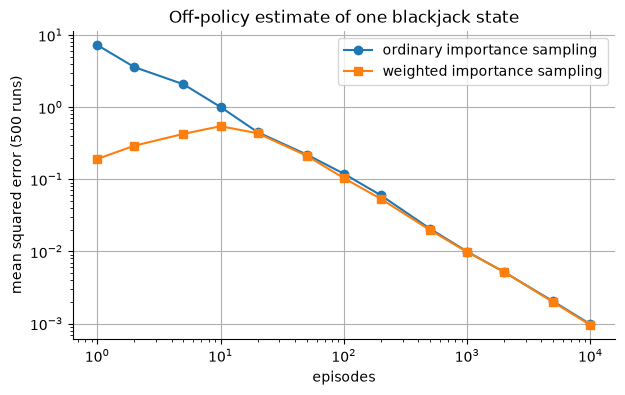

In [11]:
ordinary, weighted = running_estimates(g_off.reshape(N_STATE_RUNS, -1), rho_off.reshape(N_STATE_RUNS, -1), N_GRID)
sq_ord, sq_w = (ordinary - v_state) ** 2, (weighted - v_state) ** 2
paired = sq_ord - sq_w
paired_z = paired.mean(axis=0) / (paired.std(axis=0) / np.sqrt(N_STATE_RUNS))
print(f"{'episodes':>9}{'MSE ordinary':>14}{'MSE weighted':>14}{'difference':>12}{'paired SE':>11}{'paired z':>10}")
for j, n in enumerate(N_GRID):
    print(
        f"{n:>9}{sq_ord[:, j].mean():>14.5f}{sq_w[:, j].mean():>14.5f}{paired[:, j].mean():>12.5f}{paired[:, j].std() / np.sqrt(N_STATE_RUNS):>11.5f}{paired_z[j]:>10.2f}"
    )
z_first = [(est[:, 0].mean() - v_state) / (est[:, 0].std() / np.sqrt(N_STATE_RUNS)) for est in (ordinary, weighted)]
print(
    f"After one episode: mean over {N_STATE_RUNS} runs ordinary {ordinary[:, 0].mean():.4f} (standardized error {z_first[0]:.2f}), weighted {weighted[:, 0].mean():.4f} (standardized error {z_first[1]:.2f}), exact {v_state:.4f}"
)
late = [j for j, n in enumerate(N_GRID) if n >= N_VARIANCE_MIN]
var_ratio = np.array([sq_ord[:, j].mean() * N_GRID[j] / var_exact for j in late])
z_n1 = (sq_ord[:, 0].mean() - var_exact) / (sq_ord[:, 0].std() / np.sqrt(N_STATE_RUNS))
var_tol = Z_LIMIT * np.sqrt(2 / N_STATE_RUNS)
print(f"Ordinary MSE times n over the exact variance of one scaled return, n >= {N_VARIANCE_MIN}: {np.round(var_ratio, 3).tolist()} (expected 1 within {var_tol:.3f}); at n = 1 the MSE {sq_ord[:, 0].mean():.3f} against {var_exact:.3f} (standardized error {z_n1:.2f}, heavy-tailed, weak evidence)")

fig, ax = plt.subplots()
ax.loglog(N_GRID, sq_ord.mean(axis=0), "o-", label="ordinary importance sampling")
ax.loglog(N_GRID, sq_w.mean(axis=0), "s-", label="weighted importance sampling")
ax.set(
    xlabel="episodes",
    ylabel=f"mean squared error ({N_STATE_RUNS} runs)",
    title="Off-policy estimate of one blackjack state",
)
ax.legend()
plt.show()

### Reading the result

- The simulator is consistent with the exact value: the on-policy mean is -0.27737 (standard error 0.00042) against the exact -0.27720, and the off-policy mean of the scaled returns is -0.27774 (standard error 0.00142), standardized errors -0.39 and -0.38. All on-policy ratios equal 1, as they must.
- The book's value -0.27726 came from 100,000,000 on-policy episodes, a standard error of 0.00009 at the simulated return variance. The exact value differs from it by 0.00006, within that error, so the rules used here (infinite deck, dealer rule) reproduce the book's number for this state.
- Only 0.1414 of the off-policy episodes have a nonzero ratio, the largest is 256 (eight agreeing decisions), and one scaled return has variance 10.148 (the exact value, computed by recursion, is 10.156), which is 11.6 times the 0.873 of one on-policy return. This is the price of reweighting.
- After one episode the ordinary estimate is unbiased: mean -0.2480 over 500 runs (standardized error 0.24). The weighted estimate has mean -0.0240 against the exact -0.2772 (standardized error 15.86): it is biased, mostly because 0.8586 of the single episodes have ratio 0 and then give the estimate 0.
- In the error table the weighted MSE is far lower early: 0.19154 against 7.26735 after one episode, 0.54469 against 1.00387 after ten. At the fixed early set 1, 2, 5 and 10 the paired z values are 3.22, 5.24, 4.14 and 4.07, all above the Bonferroni limit 2.5; the value at 1 episode is the weakest (heavy tails: the ordinary MSE there is 7.267, 1.31 standard errors below the exact variance 10.156). The weighted error first rises (0.19154, 0.29200, 0.42636, 0.54469 at 1, 2, 5, 10 episodes) and then falls; in the book's figure the weighted curve also has a low hump in the first tens of episodes (by eye).
- From 20 to 50 episodes the difference is not a finding (paired z 0.38 and 0.36). At 100 and 200 episodes weighted is lower in the sample by 0.01546 and 0.00649, but with paired z 2.34 and 2.92 this is not distinguishable from zero at the limit of 3 for 13 table points; from 500 episodes on the paired z values are at most 1.52 in absolute value, and the two MSE values are 0.00098 and 0.00095 after 10,000 episodes. So the weighted estimator is much better for small samples and barely better afterwards. The book calls it much lower overall; its curves are also hard to tell apart after about a hundred episodes (by eye).
- The ordinary MSE times $n$, divided by the exact variance of one scaled return, is 0.979, 1.016, 0.995 and 0.961 at 1000, 2000, 5000 and 10,000 episodes, within the allowed 0.190 of 1: the error of ordinary importance sampling is the unbiased $\sigma^2/n$.
- The plot shows both curves on logarithmic axes: the ordinary one starts far higher, the weighted one rises to its hump near 10 episodes, and from about 20 episodes on the two are close (by eye), with the weighted one slightly lower around 100 to 200 episodes.

## 4. Infinite variance of ordinary importance sampling

The chapter's second example shows that ordinary importance sampling, though unbiased, can be extremely unstable. Its mean is finite, so by the law of large numbers the estimate does converge almost surely, but with infinite variance its error has no usable scale and the convergence is extremely slow (the book's wording, that the estimates fail to converge, is looser than that). There is one nonterminal state $s$ and two actions. `end` terminates at once with reward 0. `back` returns to $s$ with probability 0.9 and otherwise terminates with reward $+1$. The target always plays `back`, so $v_\pi(s) = 1$; the behavior plays each action with probability 1/2.

- An episode that ends with `back` after $k$ loops back to $s$ has return 1 and ratio $2^{k+1}$, and an episode that plays `end` has ratio 0. So a scaled return is 0 or $2^{k+1}$, and its mean is exactly 1.
- Its second moment is the sum, over $k$, of the episode's probability $0.45^k \cdot 0.05$ times the squared ratio $4^{k+1}$:

$$
\mathbb{E}\big[(\rho G)^2\big] = 0.1 \sum_{k=0}^{\infty} 0.9^k \cdot 2^k \cdot 2 = 0.2 \sum_{k=0}^{\infty} 1.8^k = \infty
$$

  With a finite mean, the variance is infinite exactly when the second moment is, so ordinary importance sampling has infinite variance here.
- The estimate uses the first visit to $s$, which is the start of the episode, so each episode gives one scaled return.
- Weighted importance sampling divides by the sum of the ratios. Every episode with a nonzero ratio has return 1, so from the first such episode on the estimate is exactly 1.

Implementation: `loop_episodes` plays all episodes step by step with numpy. A simulation cannot prove an infinite variance, so the evidence is the series itself, the slow shrinking of the error, and the runs ending on one side of 1. Two checks guard the simulator: the share of episodes ending with `back` must be $0.05 / 0.55 = 1/11$ (a binomial standard error), and the mean of the scaled returns of episodes of at most $K$ steps (bounded, hence with finite variance, and with exact mean $1 - 0.9^K$) must match it, with the standard error computed from the exact closed-form second moment $0.2 \sum_{k<K} 1.8^k$, not from a sample. The cut was first set to $K = 10$ and moved to 6 after the first draft showed a standardized error of -2.50 there; the move was not needed to pass (the limit is 3), so the notebook prints the standardized errors for every cut from 4 to 15 and requires all of them within the limit.

Tolerances: the square-root law would shrink the error by a factor $\sqrt{1000} = 31.6$ from 1000 to 1,000,000 episodes, so the notebook asks only that it shrinks by less than a factor of 10: a coarse threshold between the observed 0.36 and 0.03 that catches only a gross error. If the ten final estimates were scattered symmetrically around 1, at least 9 of them below 1 would have probability $11/1024 \approx 1\%$.

Where this differs from the book: ten runs of 1,000,000 episodes instead of 100,000,000, so the right part of the book's figure is not reproduced. Both estimators see the same episodes in each run.

In [12]:
def loop_episodes(n: int, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """`n` episodes of the one-state task under the behavior policy: ratio rho, return G and number of steps.

    The target always plays back, so a step with `end` has ratio 0 and a step with `back` has ratio 1 / P_UNIFORM.
    Draw order in each round: one uniform per live episode for the action, then one for the transition of `back`.
    """
    rho, g, steps = np.ones(n), np.zeros(n), np.zeros(n, dtype=int)
    live = np.arange(n)
    while live.size:
        steps[live] += 1
        back = rng.random(live.size) < P_UNIFORM
        rho[live] *= np.where(back, 1 / P_UNIFORM, 0.0)
        stays = back & (rng.random(live.size) < P_STAY)
        g[live[back & ~stays]] = 1.0
        live = live[stays]
    return rho, g, steps


def expected_square_term(k: int) -> float:
    """Contribution of the episodes with k loops back to s to E[(rho G)^2]: their probability times the squared ratio."""
    return (P_UNIFORM * P_STAY) ** k * P_UNIFORM * (1 - P_STAY) * (1 / P_UNIFORM) ** (2 * (k + 1))

In [13]:
runs = [loop_episodes(N_LOOP_EPISODES, rng) for rng in child_rngs(SEED_LOOP, N_LOOP_RUNS)]
rho_loop, g_loop, steps_loop = (np.array(x) for x in zip(*runs))
scaled_loop = rho_loop * g_loop
cum_scaled, cum_w = np.cumsum(scaled_loop, axis=1), np.cumsum(rho_loop, axis=1)
path_ord = cum_scaled / np.arange(1, N_LOOP_EPISODES + 1)
path_w = np.divide(cum_scaled, cum_w, out=np.zeros_like(path_ord), where=cum_w > 0)
first = (rho_loop > 0).argmax(axis=1) + 1
weighted_exact = bool((path_w[cum_w > 0] == 1).all())
p_match = P_UNIFORM * (1 - P_STAY) / (1 - P_UNIFORM * P_STAY)
z_match = (np.mean(rho_loop > 0) - p_match) / np.sqrt(p_match * (1 - p_match) / rho_loop.size)


def cut_z(k: int) -> tuple[float, float, float]:
    """Mean of the scaled returns of episodes of at most `k` steps, its exact mean 1 - P_STAY^k, and the standardized error.

    The exact standard error uses the closed-form second moment, the sum of `expected_square_term` over fewer than `k` loops.
    """
    mean_exact = 1 - P_STAY**k
    var_exact_cut = sum(expected_square_term(j) for j in range(k)) - mean_exact**2
    mean = float((scaled_loop * (steps_loop <= k)).mean())
    return mean, mean_exact, (mean - mean_exact) / np.sqrt(var_exact_cut / scaled_loop.size)


cut_table = {k: cut_z(k) for k in range(CUT_FIRST, CUT_LAST + 1)}
cut_mean, exact_cut, z_cut = cut_table[CUT_STEPS]
z_cut_range = [v[2] for v in cut_table.values()]

Partial sums of E[(rho G)^2] over the first m terms of the series 0.1 * sum 0.9^k 2^k 2: {5: 4.5, 10: 89.0, 20: 31870.3, 40: 4062938165.5}; each term is 1.8 times the one before
Simulator check: share of episodes ending with back 0.09085 against exact 1/11 = 0.09091 (standardized error -0.63)
Episodes of at most 6 steps only: mean of the scaled return 0.4675 against exact 0.4686 (standardized error from the exact variance -1.14); longest of the 10,000,000 episodes 21 steps
Standardized errors of that mean for every cut from 4 to 15 steps: [-0.8, -0.73, -1.14, -1.31, -0.79, -1.07, -2.42, -1.66, -1.44, -2.15, -1.18, -1.63]
Weighted estimate: first consistent episode of each run [7, 9, 11, 11, 13, 3, 8, 19, 1, 16]; from there on, the estimate equals 1 exactly at every episode: True
 episodes     min  median     max  below 1  median |error|   (ordinary estimates of v_pi(s) = 1, 10 runs)
       10   0.000   0.100   1.600        9           0.900
      100   0.240   0.480   2.260        9   

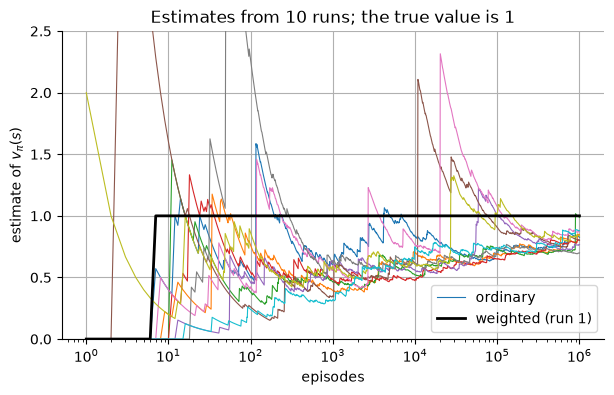

In [14]:
series = {m: round(sum(expected_square_term(k) for k in range(m)), 1) for m in SERIES_TERMS}
print(f"Partial sums of E[(rho G)^2] over the first m terms of the series 0.1 * sum 0.9^k 2^k 2: {series}; each term is {expected_square_term(5) / expected_square_term(4):.1f} times the one before")
print(
    f"Simulator check: share of episodes ending with back {np.mean(rho_loop > 0):.5f} against exact 1/11 = {p_match:.5f} (standardized error {z_match:.2f})"
)
print(
    f"Episodes of at most {CUT_STEPS} steps only: mean of the scaled return {cut_mean:.4f} against exact {exact_cut:.4f} (standardized error from the exact variance {z_cut:.2f}); longest of the {rho_loop.size:,} episodes {steps_loop.max()} steps"
)
print(f"Standardized errors of that mean for every cut from {CUT_FIRST} to {CUT_LAST} steps: {[round(float(z), 2) for z in z_cut_range]}")
print(f"Weighted estimate: first consistent episode of each run {first.tolist()}; from there on, the estimate equals 1 exactly at every episode: {weighted_exact}")
print(
    f"{'episodes':>9}{'min':>8}{'median':>8}{'max':>8}{'below 1':>9}{'median |error|':>16}   (ordinary estimates of v_pi(s) = 1, {N_LOOP_RUNS} runs)"
)
at = np.array(LOOP_GRID) - 1
for n, col in zip(LOOP_GRID, path_ord[:, at].T):
    print(
        f"{n:>9}{col.min():>8.3f}{np.median(col):>8.3f}{col.max():>8.3f}{int((col < 1).sum()):>9}{np.median(np.abs(col - 1)):>16.3f}"
    )
shrink = np.median(np.abs(path_ord[:, at[2]] - 1)) / np.median(np.abs(path_ord[:, at[-1]] - 1))
print(f"Median |error| from {LOOP_GRID[2]:,} to {LOOP_GRID[-1]:,} episodes falls by the factor {shrink:.2f}; the square-root law would give {np.sqrt(LOOP_GRID[-1] / LOOP_GRID[2]):.1f}")
print("Checkpoint: from its first consistent episode on, weighted importance sampling is exactly 1 (partly tautological: the numerator and denominator are sums of the same numbers):", weighted_exact)

grid_plot = np.unique(np.geomspace(1, N_LOOP_EPISODES, PLOT_POINTS).astype(int)) - 1
fig, ax = plt.subplots()
for k in range(N_LOOP_RUNS):
    ax.semilogx(grid_plot + 1, path_ord[k, grid_plot], lw=0.8, label="ordinary" if k == 0 else None)
ax.semilogx(grid_plot + 1, path_w[0, grid_plot], "k", lw=2, label="weighted (run 1)")
ax.set(
    ylim=(0, 2.5),
    xlabel="episodes",
    ylabel="estimate of $v_\\pi(s)$",
    title=f"Estimates from {N_LOOP_RUNS} runs; the true value is 1",
)
ax.legend()
plt.show()

### Reading the result

- The series of the expected square does not settle: its partial sums are 4.5 after 5 terms, 89.0 after 10, 31870.3 after 20 and 4062938165.5 after 40, each term being 1.8 times the one before. The second moment is infinite, so the variance is.
- The simulator is consistent with the exact values: the share of episodes ending with `back` is 0.09085 against $1/11 = 0.09091$ (standardized error -0.63), and the scaled returns of episodes of at most 6 steps have mean 0.4675 against the exact 0.4686 (standardized error -1.14 from the exact variance). Over all cuts from 4 to 15 steps the standardized errors lie between -2.42 (at 10 steps) and -0.73. The longest of the 10,000,000 simulated episodes was 21 steps.
- Weighted importance sampling is exactly 1 in every run from its first consistent episode on (episodes 7, 9, 11, 11, 13, 3, 8, 19, 1 and 16), with the estimate equal to 1 exactly. This check is partly tautological: the numerator and denominator are sums of the same numbers, because every consistent episode has return 1.
- Ordinary importance sampling is not near 1. After 1000 episodes all ten runs are below 1 (0.316 to 0.628, median 0.535); after 1,000,000 they are still all below 1 (0.699 to 0.988, median 0.831). The median absolute error only falls from 0.465 to 0.169, a factor 2.75 for a thousandfold increase, where the square-root law of a finite-variance average would give 31.6.
- It is not always below 1: after 100,000 episodes three runs are above 1 (the largest 1.074), and after 100 episodes the largest is 2.260. In the plot (by eye) most runs first fall to about 0.5 within a few hundred episodes and then creep upward with sudden jumps, each followed by a slow decay, when a rare long episode arrives; the weighted line (run 1) is 0 until its first consistent episode and exactly 1 afterwards.
- A likely reason that typical estimates stay below the mean is that the mean of 1 is carried by rare episodes with enormous ratios; most samples do not contain them. This explanation is not tested here.
- This notebook's data end at 1,000,000 episodes, where all ten estimates are between 0.699 and 0.988. The book's figure goes to 100,000,000 episodes, and by eye its runs there are tightly clustered near 0.9 to 1.0; that right half is not reproduced here, so these data do not say whether the estimates have settled by then.

## 5. Incremental evaluation with weighted importance sampling

Monte Carlo prediction can be computed episode by episode. For weighted importance sampling the running weighted average $V_n$ needs, besides $V_n$, the cumulative weight $C_n$:

$$
V_{n+1} = V_n + \frac{W_n}{C_n}\big[ G_n - V_n \big], \qquad C_{n+1} = C_n + W_{n+1}, \qquad C_0 = 0
$$

- $G_n$ is the $n$-th return of the state and $W_n$ its weight, typically the ratio. The step size $W_n / C_n$ shrinks as weight accumulates; each new return pulls $V$ toward it in proportion to its weight relative to all weight so far. $V_1$ is arbitrary.

The evaluation algorithm applies this to action values for every state-action pair. It keeps $Q(s,a)$ and $C(s,a)$ and handles an episode by sweeping backward from the last step, with $G \leftarrow 0$ and $W \leftarrow 1$ ($\gamma$ is the discount rate, 1 in blackjack):

$$
G \leftarrow \gamma G + R_{t+1}, \quad C(S_t,A_t) \leftarrow C(S_t,A_t) + W, \quad Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \frac{W}{C(S_t,A_t)}\big[G - Q(S_t,A_t)\big], \quad W \leftarrow W \frac{\pi(A_t|S_t)}{\mu(A_t|S_t)}
$$

and stops the sweep when $W = 0$, because nothing earlier can contribute.

- At the update of step $t$, $W$ holds the ratio of the steps after $t$ only. The action value already conditions on $A_t$, so the probability of $A_t$ must not enter its own weight; it is applied afterwards, for the earlier steps.
- It is an every-visit method.
- With $\pi = \mu$ every $W$ is 1 and the algorithm is on-policy evaluation, the plain average of returns.

Experiments: first the incremental rule on its own, then the algorithm on blackjack with the target of the previous section (stick on 20 or 21) and the random behavior policy, on games played from the deal (naturals are left out, since no decision is made in them). `behavior_episodes` plays them one by one in plain Python from one stream of uniform numbers (the draw order is in its docstring).

Checks, of two kinds:

- *Consistency of two code paths* (not independent evidence): the algorithm against the batch formula computed with explicit products of ratios, with and without discounting, and against the plain average for $\pi = \mu$. They compute the same quantity by different routes.
- *Independent*: the estimates against the exact $q_\pi$ from DP. The standard error of the weighted estimate of a pair is $\sqrt{\sum_i \rho_i^2 (G_i - V)^2} / \sum_i \rho_i$, an approximation for many returns. The *effective sample size* $(\sum \rho)^2 / \sum \rho^2$ is the number of equally weighted returns that would give the same variance; the check covers pairs with an effective sample size of at least 100, chosen from the weights alone and not from the errors. With about 335 pairs, requiring every one within 3 standard errors would fail by chance in about 60% of runs (335 x 0.0027 = 0.9 expected exceedances), so the check requires a share of at least 97%. Pairs whose return is deterministic have a standard error of 0 and must match exactly.

In [15]:
def weighted_average_incremental(returns: np.ndarray, weights: np.ndarray) -> float:
    """V_n by the update V <- V + (W / C)(G - V) with C the running sum of the weights; the same estimate as `weighted_is`."""
    v, c = 0.0, 0.0
    for g, w in zip(returns, weights):
        c += w
        if w > 0:
            v += w / c * (g - v)
    return v


def off_policy_evaluation(episodes: tuple, pi: list, mu: list, gamma: float = 1.0) -> tuple[list, list]:
    """The incremental every-visit algorithm: Q[s][a] estimates q_pi(s, a) from episodes generated by mu, plus the weights C.

    `episodes` are the flat lists (states, actions, ends, finals) of `behavior_episodes`; `pi[s][a]` and `mu[s][a]` are the
    action probabilities of the target and behavior policies. Only the last reward of a blackjack game is nonzero.
    """
    states, acts, ends, finals = episodes
    q, c = [[0.0, 0.0] for _ in range(N_STATES)], [[0.0, 0.0] for _ in range(N_STATES)]
    lo = 0
    for hi, final in zip(ends, finals):
        g, w = 0.0, 1.0
        for t in range(hi - 1, lo - 1, -1):
            s, a = states[t], acts[t]
            g = gamma * g + (final if t == hi - 1 else 0.0)
            c[s][a] += w
            q[s][a] += w / c[s][a] * (g - q[s][a])
            w *= pi[s][a] / mu[s][a]
            if w == 0:
                break
        lo = hi
    return q, c

In [16]:
rng_check, rng_eval = child_rngs(SEED_EVAL, 2)
data = rng_check.normal(size=N_RANDOM)
weights = rng_check.pareto(PARETO_SHAPE, N_RANDOM) * (rng_check.random(N_RANDOM) < P_NONZERO)
gap_inc = abs(weighted_average_incremental(data, weights) - weighted_is(data, weights))
print(
    f"Chapter example (+1 with weight 10, then -1 with weight 0.5): incremental {weighted_average_incremental(TWO_RETURNS, TWO_RATIOS):.4f}, batch {weighted_is(TWO_RETURNS, TWO_RATIOS):.4f}"
)
print(
    f"{N_RANDOM} random returns with heavy-tailed weights, {1 - P_NONZERO:.0%} of them zero: difference between the two forms {gap_inc:.1e}"
)
print(
    "Checkpoint: the incremental rule reproduces the batch weighted average (consistency of two code paths):",
    gap_inc < AGREE_TOL,
)

Chapter example (+1 with weight 10, then -1 with weight 0.5): incremental 0.9048, batch 0.9048
1000 random returns with heavy-tailed weights, 70% of them zero: difference between the two forms 0.0e+00
Checkpoint: the incremental rule reproduces the batch weighted average (consistency of two code paths): True


In [17]:
def uniform_stream(rng: np.random.Generator) -> Iterator[float]:
    """Endless stream of uniform random numbers drawn in batches."""
    while True:
        yield from rng.random(CHUNK).tolist()


def dealer_final(up: int, card: Callable[[], int]) -> int:
    """Dealer's final total (above 21 is bust) for a hand showing `up`, drawing cards with `card()`."""
    d, d_ace = up + (hole := card()), up == 1 or hole == 1
    while total(d, d_ace) < DEALER_STAND:
        c = card()
        d, d_ace = d + c, d_ace or c == 1
    return total(d, d_ace)

In [18]:
def behavior_episodes(n: int, rng: np.random.Generator) -> tuple[list, list, list, list]:
    """`n` games from the deal under the random behavior policy; naturals are dropped (no decision is made in them).

    Returns flat lists: the state index ((sum - 12) * 10 + dealer - 1) * 2 + usable and the action of every decision,
    the position in those lists where each game ends, and each game's reward (given on its last step, no discounting).
    Every card and every coin comes from one stream of uniforms: card = min(int(13 u) + 1, TEN), hit if u < 1/2.
    """
    u = uniform_stream(rng)

    def card() -> int:
        """Next card value from the stream."""
        return min(int(next(u) * N_RANKS) + 1, TEN)

    states, acts, ends, finals = [], [], [], []
    while len(ends) < n:
        up, c1, c2 = card(), card(), card()
        h, ace = c1 + c2, c1 == 1 or c2 == 1
        if total(h, ace) == BLACKJACK:
            continue
        while total(h, ace) < FIRST_DECISION:
            c = card()
            h, ace = h + c, ace or c == 1
        while True:
            t, usable = total(h, ace), int(ace and h + ACE_BONUS <= BLACKJACK)
            a = HIT if next(u) < P_UNIFORM else STICK
            states.append(((t - FIRST_DECISION) * N_UP + up - 1) * 2 + usable)
            acts.append(a)
            if a == STICK:
                dealer = dealer_final(up, card)
                final = 1.0 if dealer > BLACKJACK else float((t > dealer) - (t < dealer))
                break
            c = card()
            h, ace = h + c, ace or c == 1
            if h > BLACKJACK:
                final = -1.0
                break
        ends.append(len(acts))
        finals.append(final)
    return states, acts, ends, finals

In [19]:
def first_episodes(episodes: tuple, n: int) -> tuple:
    """The first `n` games of a flat episode set."""
    states, acts, ends, finals = episodes
    return states[: ends[n - 1]], acts[: ends[n - 1]], ends[:n], finals[:n]


def weighted_is_batch(
    episodes: tuple, pi: list, mu: list, gamma: float = 1.0
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Every-visit records (pair index 2s + a, ratio of the later steps only, return G_t) with a nonzero ratio, by explicit products."""
    states, acts, ends, finals = episodes
    pair, rho, ret = [], [], []
    lo = 0
    for hi, final in zip(ends, finals):
        for t in range(lo, hi):
            r = 1.0
            for k in range(t + 1, hi):
                r *= pi[states[k]][acts[k]] / mu[states[k]][acts[k]]
            if r > 0:
                pair.append(2 * states[t] + acts[t])
                rho.append(r)
                ret.append(gamma ** (hi - 1 - t) * final)
        lo = hi
    return np.array(pair), np.array(rho), np.array(ret)


def pair_estimates(pair: np.ndarray, rho: np.ndarray, ret: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Weighted estimate per pair, its standard error (ratio-estimator formula) and the effective sample size (sum rho)^2 / sum rho^2."""
    m = 2 * N_STATES
    den, sq = np.bincount(pair, rho, m), np.bincount(pair, rho**2, m)
    est = np.divide(np.bincount(pair, rho * ret, m), den, out=np.zeros(m), where=den > 0)
    se = np.sqrt(np.bincount(pair, (rho * (ret - est[pair])) ** 2, m)) / np.maximum(den, TINY)
    return est, se, np.divide(den**2, sq, out=np.zeros(m), where=sq > 0)

In [20]:
episodes = behavior_episodes(N_EVAL, rng_eval)
pi_target = np.stack([1 - P_HIT_TARGET, P_HIT_TARGET], axis=-1).reshape(N_STATES, 2).tolist()
mu_random = [[1 - P_UNIFORM, P_UNIFORM]] * N_STATES
q_box, c_box = off_policy_evaluation(episodes, pi_target, mu_random)
est, se, ess = pair_estimates(*weighted_is_batch(episodes, pi_target, mu_random))
gap_batch = np.abs(np.array(q_box).reshape(-1) - est)[np.array(c_box).reshape(-1) > 0].max()

short = first_episodes(episodes, N_EVAL_GAMMA)
est_g = pair_estimates(*weighted_is_batch(short, pi_target, mu_random, GAMMA_CHECK))[0]
q_g, c_g = off_policy_evaluation(short, pi_target, mu_random, GAMMA_CHECK)
gap_gamma = np.abs(np.array(q_g).reshape(-1) - est_g)[np.array(c_g).reshape(-1) > 0].max()

q_on, _ = off_policy_evaluation(episodes, mu_random, mu_random)
pairs_flat = 2 * np.array(episodes[0]) + np.array(episodes[1])
g_flat = np.repeat(episodes[3], np.diff(np.concatenate([[0], episodes[2]])))
visits = np.bincount(pairs_flat, minlength=2 * N_STATES)
mean_g = np.divide(np.bincount(pairs_flat, g_flat, 2 * N_STATES), visits, out=np.zeros(2 * N_STATES), where=visits > 0)
gap_on = np.abs(np.array(q_on).reshape(-1) - mean_g)[visits > 0].max()

In [21]:
truth = q_target.reshape(-1)
checked = ess >= ESS_MIN
within = np.abs(est - truth) <= Z_LIMIT * se + AGREE_TOL
z = ((est - truth) / np.where(se > 0, se, 1))[checked & (se > 0)]
z_share = float(within[checked].mean())

In [22]:
print(
    f"{N_EVAL:,} behavior episodes, {len(episodes[0]):,} decisions; pairs with a nonzero weight {int((ess > 0).sum())} of {2 * N_STATES}, checked (effective sample size >= {ESS_MIN}) {int(checked.sum())}"
)
print(
    f"Incremental algorithm against the batch formula: largest difference {gap_batch:.1e}; with discount {GAMMA_CHECK} on {N_EVAL_GAMMA:,} episodes {gap_gamma:.1e}"
)
print(
    f"On-policy special case (pi = mu): largest difference of Q to the plain average of the returns of each pair {gap_on:.1e}"
)
print(
    f"Against the exact q_pi, over the checked pairs: share within {Z_LIMIT} standard errors {z_share:.3f} (normal: 0.997); {int((checked & (se == 0)).sum())} pairs have a deterministic return, {int((~checked).sum())} pairs are not checked"
)
print(
    f"Of the other {z.size}, share within 1 standard error {np.mean(np.abs(z) < 1):.3f} (normal: 0.683), largest |z| {np.abs(z).max():.2f}"
)
print(
    f"Effective sample size of the checked pairs: median {np.median(ess[checked]):.0f}, fewest {ess[checked].min():.0f}; mean absolute error {np.abs(est - truth)[checked].mean():.4f}"
)
print(
    "Checkpoint: incremental and batch estimates agree (consistency of two code paths):",
    bool(max(gap_batch, gap_gamma, gap_on) < AGREE_TOL),
)

500,000 behavior episodes, 636,637 decisions; pairs with a nonzero weight 400 of 400, checked (effective sample size >= 100) 335
Incremental algorithm against the batch formula: largest difference 2.4e-15; with discount 0.9 on 20,000 episodes 7.8e-16
On-policy special case (pi = mu): largest difference of Q to the plain average of the returns of each pair 2.8e-15
Against the exact q_pi, over the checked pairs: share within 3 standard errors 1.000 (normal: 0.997); 10 pairs have a deterministic return, 65 pairs are not checked
Of the other 325, share within 1 standard error 0.702 (normal: 0.683), largest |z| 2.96
Effective sample size of the checked pairs: median 1209, fewest 101; mean absolute error 0.0260
Checkpoint: incremental and batch estimates agree (consistency of two code paths): True


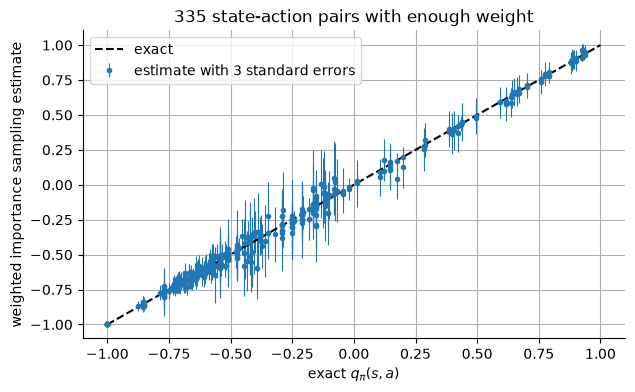

In [23]:
fig, ax = plt.subplots()
ax.errorbar(
    truth[checked],
    est[checked],
    yerr=Z_LIMIT * se[checked],
    fmt="o",
    ms=3,
    lw=0.8,
    label=f"estimate with {Z_LIMIT} standard errors",
)
ax.plot([-1, 1], [-1, 1], "k--", label="exact")
ax.set(
    xlabel="exact $q_\\pi(s, a)$",
    ylabel="weighted importance sampling estimate",
    title=f"{int(checked.sum())} state-action pairs with enough weight",
)
ax.legend()
plt.show()

### Reading the result

- The incremental rule reproduces the batch average: on the chapter's two returns both give 0.9048, and on 1000 random returns with heavy-tailed weights, 70% of them zero, the two differ by 0.0e+00.
- On blackjack, 500,000 behavior episodes give 636,637 decisions, and all 400 state-action pairs receive weight. The algorithm equals the batch formula to 2.4e-15, the discounted variant (discount 0.9, on 20,000 episodes) to 7.8e-16, and for $\pi = \mu$ it equals the plain average of each pair's returns to 2.8e-15. These checks only show that two implementations agree.
- 335 pairs have an effective sample size of at least 100 (median 1209, fewest 101); the other 65 pairs are not checked. Against the exact $q_\pi$, all of the 335 are within 3 standard errors (share 1.000; a normal distribution would give 0.997), 10 of them with a deterministic return that matches exactly. Of the other 325 pairs, 0.702 are within 1 standard error (normal: 0.683) and the largest standardized error is 2.96. The mean absolute error over the 335 pairs is 0.0260.
- The plot shows the estimates of the 335 pairs against the exact values, with 3 standard errors as bars: the points lie along the diagonal (by eye) and every 3-standard-error bar reaches it, as the share of 1.000 says.
- A deterministic target gives most episodes zero weight at early decisions: the sweep stops as soon as the behavior leaves the target's path, a likely reason why only 335 of 400 pairs reach an effective sample size of 100 even with half a million episodes (explanation, not tested).

## 6. Off-policy Monte Carlo control

Control learns a good policy while behaving differently. The behavior policy $\mu$ is any soft policy (every action has positive probability) and may change; the target $\pi$ is greedy with respect to the current $Q$. This is generalized policy iteration (GPI), alternating evaluation and improvement, with weighted importance sampling as the evaluation.

- Because $\pi$ is deterministic, $\pi(A_t|S_t)$ is 1 for the greedy action and 0 otherwise. The step factor of the weight is therefore $1 / \mu(A_t|S_t)$ for a greedy action and 0 for any other, so the weight is zero as soon as the sweep passes a non-greedy action: the method learns only from the *tail* of each episode after its last non-greedy action. If non-greedy actions are frequent, states early in long episodes learn slowly.
- Each backward step is: update $Q(S_t, A_t)$ with the current $W$, set $\pi(S_t) \leftarrow \arg\max_a Q(S_t, a)$, then multiply $W$ by $1/\mu(A_t|S_t)$ if $A_t$ is the greedy action and stop the sweep otherwise.

**A quirk of the printed algorithm.** As printed, the algorithm multiplies $W$ by $1/\mu(A_t|S_t)$ for every action and exits when $W = 0$. For a soft $\mu$ that factor is always positive, so $W$ is never 0 and the exit cannot trigger; the sweep would then cover whole episodes and count non-greedy actions as if the target took them. The text describes tail-only learning, and `mode="tail"` follows the text: the sweep stops at the first non-greedy action. To see what the quirk costs, the notebook also runs two contrasts of its own design (not in the book): `"printed"` follows the box literally, and `"unweighted"` stops at the same place but keeps $W = 1$.

Setup: the behavior is the random policy (stick or hit with equal probability), fixed, so the episodes do not depend on what is learned and all three variants see the same episodes (paired). $Q$ starts at 0, so the initial greedy policy is to stick; ties go to stick; the method is every-visit; there is no discounting. Games start from the deal and naturals are left out, as in the evaluation above. Two runs of 2,000,000 episodes each, from generators spawned from one seed; the count is a tuning choice, set partly from a first look at 300,000 episodes (8 wrong states) and the runtime budget. The book describes the method but gives no blackjack result, so the comparison is with the exact $q_*$ and optimal policy from DP only.

Checks: a state is *wrong* if the learned greedy action differs from the optimal one. The learned policy is judged by the number of wrong states, by the exact return per game it earns, and by whether every wrong decision is within sampling noise: its exact loss in action value must be below 3 standard errors of the estimated difference of its two action values. These standard errors use the weights as they were when each return arrived, and the two action values of a state are treated as independent although they come from overlapping episodes; the policy changes during learning, so the allowance is an approximation, and a wide one. A run with no wrong state would pass vacuously; here each run has one.

In [24]:
def off_policy_control(episodes: tuple, mode: str, mu: list) -> tuple:
    """Weighted-importance-sampling control: Q, effective sample sizes, standard errors and policy snapshots (hit = 1).

    mode "tail": the text's algorithm, stop the backward sweep at the first non-greedy action and weight by 1 / mu.
    mode "unweighted": the same stop, but W stays 1.  mode "printed": no stop, W <- W / mu for every action.
    Greedy ties go to stick. The standard-error sums use the weights as they were when each return arrived.
    """
    states, acts, ends, finals = episodes
    q, c, sw2, sw2g, sw2g2 = ([0.0] * (2 * N_STATES) for _ in range(5))
    pi, snaps, lo = [STICK] * N_STATES, [], 0
    for i, (hi, final) in enumerate(zip(ends, finals), 1):
        g, w = 0.0, 1.0
        for t in range(hi - 1, lo - 1, -1):
            s, a = states[t], acts[t]
            j = 2 * s + a
            g += final if t == hi - 1 else 0.0
            c[j] += w
            q[j] += w / c[j] * (g - q[j])
            sw2[j] += w * w
            sw2g[j] += w * w * g
            sw2g2[j] += w * w * g * g
            pi[s] = HIT if q[2 * s + 1] > q[2 * s] else STICK
            if mode == "printed":
                w /= mu[s][a]
            elif a != pi[s]:
                break
            elif mode == "tail":
                w /= mu[s][a]
        lo = hi
        if i % SNAPSHOT_EVERY == 0:
            snaps.append(pi[:])
    q, c, sw2 = np.array(q), np.array(c), np.array(sw2)
    var = np.maximum(np.array(sw2g2) - 2 * q * np.array(sw2g) + q**2 * sw2, 0)
    se = np.where(c > 0, np.sqrt(var) / np.maximum(c, TINY), np.inf)
    ess = np.divide(c**2, sw2, out=np.zeros_like(c), where=sw2 > 0)
    return tuple(x.reshape(N_SUMS, N_UP, 2, 2) for x in (q, ess, se)) + (np.array(snaps).reshape(-1, N_SUMS, N_UP, 2),)

In [25]:
def shortfall(pi: np.ndarray, q_true: np.ndarray) -> np.ndarray:
    """Exact loss in action value, per state, from taking the action `pi` instead of the best one."""
    return q_true.max(axis=-1) - np.take_along_axis(q_true, pi[..., None], axis=-1)[..., 0]


def assess(run: tuple, q_true: np.ndarray) -> dict:
    """Greedy policy of a run, its number of wrong states, whether each wrong decision lies within noise, and its exact return per game.

    The noise allowance treats the two action values of a state as independent and uses their standard errors as in the
    ratio-estimator formula, so it is an approximation. With no wrong state `noise_ok` is True vacuously.
    """
    q, _, se, _ = run
    pi, pi_true = (q[..., HIT] > q[..., STICK]).astype(int), (q_true[..., HIT] > q_true[..., STICK]).astype(int)
    wrong, noise = pi != pi_true, Z_LIMIT * np.sqrt((se**2).sum(axis=-1))
    noise_ok = bool((shortfall(pi, q_true)[wrong] < noise[wrong]).all()) if wrong.any() else True
    return {"pi": pi, "wrong": int(wrong.sum()), "noise_ok": noise_ok, "game": exact_values(pi.astype(float))[1]}


def wrong_list(pi: np.ndarray, pi_true: np.ndarray, q_true: np.ndarray) -> list:
    """(sum, dealer card, usable ace, exact loss) of every state where `pi` differs from `pi_true`."""
    gap = shortfall(pi, q_true)
    return [
        (int(SUMS[ti]), int(di) + 1, int(u), round(float(gap[ti, di, u]), 4))
        for ti, di, u in zip(*np.nonzero(pi != pi_true))
    ]

In [26]:
pi_opt = (q_opt[..., HIT] > q_opt[..., STICK]).astype(int)
control, snap_counts = {mode: [] for mode in MODES}, {}
for k, rng in enumerate(child_rngs(SEED_CONTROL, N_CONTROL_RUNS)):
    stream = behavior_episodes(N_CONTROL, rng)
    for mode in MODES:
        run = off_policy_control(stream, mode, mu_random)
        control[mode].append((run, assess(run, q_opt)))
        snap_counts[mode, k] = [int((s != pi_opt).sum()) for s in run[3]]

In [27]:
print(f"Optimal play returns {game_opt:.4f} per game, the random behavior policy {game_random:.4f}")
for mode in MODES:
    results = [a for _, a in control[mode]]
    print(
        f"{mode:<11} states differing from the optimal policy {[a['wrong'] for a in results]}, return per game {[round(float(a['game']), 4) for a in results]}, wrong decisions within noise {[a['noise_ok'] for a in results]} (vacuous if no wrong state)"
    )
for k, (_, a) in enumerate(control["tail"], 1):
    print(f"  run {k}, tail: wrong states (sum, dealer, usable ace, exact loss) {wrong_list(a['pi'], pi_opt, q_opt)}")
print(f"States where the policy is not optimal after every {SNAPSHOT_EVERY:,} episodes, run 1:")
for mode in MODES:
    print(f"  {mode:<11}{snap_counts[mode, 0]}")
q_run, ess_run = control["tail"][0][0][:2]
print(
    f"Run 1, tail: effective sample size per pair median {np.median(ess_run):.0f}, fewest {ess_run.min():.0f}; root-mean-square error of Q against q_* {np.sqrt(np.mean((q_run - q_opt) ** 2)):.4f}"
)

Optimal play returns -0.0431 per game, the random behavior policy -0.3591
tail        states differing from the optimal policy [1, 1], return per game [-0.0431, -0.0433], wrong decisions within noise [True, True] (vacuous if no wrong state)
unweighted  states differing from the optimal policy [20, 19], return per game [-0.0654, -0.0642], wrong decisions within noise [False, False] (vacuous if no wrong state)
printed     states differing from the optimal policy [32, 35], return per game [-0.0601, -0.0596], wrong decisions within noise [False, False] (vacuous if no wrong state)
  run 1, tail: wrong states (sum, dealer, usable ace, exact loss) [(12, 4, 0, 0.0025)]
  run 2, tail: wrong states (sum, dealer, usable ace, exact loss) [(12, 3, 0, 0.0186)]
States where the policy is not optimal after every 100,000 episodes, run 1:
  tail       [18, 8, 6, 10, 7, 7, 4, 3, 3, 4, 3, 3, 3, 3, 3, 3, 2, 3, 1, 1]
  unweighted [27, 22, 19, 19, 20, 19, 18, 19, 19, 19, 19, 20, 19, 19, 19, 19, 19, 20, 20, 2

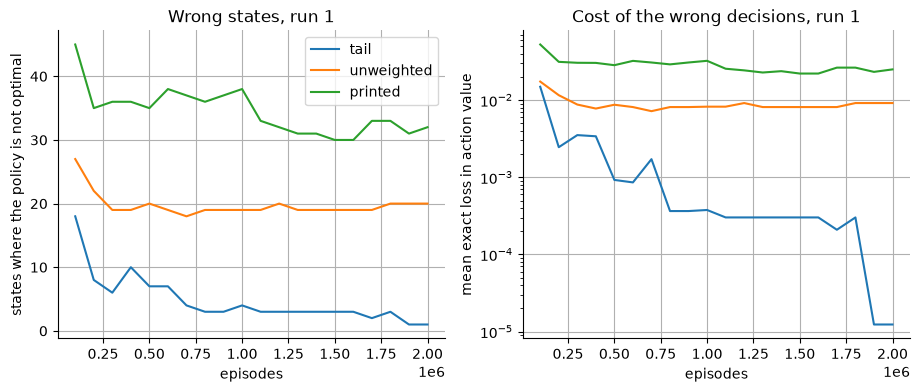

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
axis = SNAPSHOT_EVERY * np.arange(1, len(snap_counts["tail", 0]) + 1)
for mode in MODES:
    ax1.plot(axis, snap_counts[mode, 0], label=mode)
    ax2.plot(axis, [shortfall(s, q_opt).mean() for s in control[mode][0][0][3]], label=mode)
ax1.set(xlabel="episodes", ylabel="states where the policy is not optimal", title="Wrong states, run 1")
ax2.set(
    xlabel="episodes",
    ylabel="mean exact loss in action value",
    title="Cost of the wrong decisions, run 1",
    yscale="log",
)
ax1.legend()
plt.show()

### Reading the result

- The text's algorithm ends with 1 wrong state of 200 in each run, and earns -0.0431 and -0.0433 per game against -0.0431 for optimal play and -0.3591 for the random behavior it learned from. The wrong states are near ties: hard 12 against a dealer 4 in run 1 (exact loss 0.0025) and hard 12 against a dealer 3 in run 2 (loss 0.0186). In both runs every wrong decision is within sampling noise.
- The two contrasts fail clearly. Without weights, 20 and 19 states are wrong and the return is -0.0654 and -0.0642; with the box as printed, 32 and 35 states are wrong and the return is -0.0601 and -0.0596. Their wrong decisions are not within noise in any run. So the importance weights and the tail-only stop both matter here.
- In run 1 the count of wrong states for the text's algorithm, printed every 100,000 episodes, goes 18, 8, 6, 10, 7, 7, 4, 3, 3, 4, 3, 3, 3, 3, 3, 3, 2, 3, 1, 1. It falls but not monotonically (6 to 10, 3 to 4, and 2 to 3), and reaches 1 only in the last two printed values: learning is slow, in line with the chapter's warning about tail-only learning. From the third printed value on, the unweighted variant stays between 18 and 20 wrong states, and from the second on the printed one stays between 30 and 38, so they do not improve with more data. Two runs show a clear tendency toward the optimal policy, not convergence.
- Run 1's weights are worth a median of 4572 equally weighted returns per pair (fewest 97), and its action values have a root-mean-square error of 0.0267 against $q_*$. A likely reason this is larger than the sampling error alone is that early returns were weighted under policies that have since changed; this explanation is not tested here.
- The left plot shows the wrong-state counts of the three variants in run 1; the right plot (logarithmic axis) shows the mean exact loss in action value, which falls for the text's algorithm and stays high for the contrasts (by eye).

## 7. Importance sampling on truncated returns

With discounting, $\gamma < 1$, the ratio of a whole episode can be wasteful. If $\gamma = 0$ the return is just $R_1$, yet its ratio is a product of one factor per step. Factors for steps after the reward is determined are independent of the return and have expectation 1: they leave the expected update unchanged but add variance, sometimes infinite.

The remedy treats discounting as a probability of termination. A *flat partial return* is the undiscounted sum of rewards from $t$ up to a horizon $h$, $\bar G_t^h = R_{t+1} + \dots + R_h$, and the discounted return is a mixture of flat partial returns, weighted by the degree of termination at each horizon:

$$
G_t = \gamma^{T-t-1} \bar G_t^T + (1-\gamma) \sum_{h=t+1}^{T-1} \gamma^{h-t-1} \bar G_t^h
$$

Each flat partial return is scaled only by the ratio up to its own horizon, $\rho_t^h = \prod_{k=t}^{h-1} \pi(A_k|S_k) / \mu(A_k|S_k)$. The truncated ordinary estimator and the truncated weighted estimator are

$$
V_{\text{ordinary}}(s) = \frac{\sum_{t \in \mathcal{T}(s)} \Big( \gamma^{T(t)-t-1} \rho_t^{T(t)} \bar G_t^{T(t)} + (1-\gamma) \sum_{h=t+1}^{T(t)-1} \gamma^{h-t-1} \rho_t^{h} \bar G_t^{h} \Big)}{|\mathcal{T}(s)|}, \qquad
V_{\text{weighted}}(s) = \frac{\sum_{t \in \mathcal{T}(s)} \Big( \gamma^{T(t)-t-1} \rho_t^{T(t)} \bar G_t^{T(t)} + (1-\gamma) \sum_{h} \gamma^{h-t-1} \rho_t^{h} \bar G_t^{h} \Big)}{\sum_{t \in \mathcal{T}(s)} \Big( \gamma^{T(t)-t-1} \rho_t^{T(t)} + (1-\gamma) \sum_{h} \gamma^{h-t-1} \rho_t^{h} \Big)}
$$

where the sum over $h$ runs from $t+1$ to $T(t)-1$. The weighted estimator keeps the numerator and divides by the same sum with every $\bar G$ left out.

The book gives no experiment for this idea, so the task below is this notebook's own: one state $s$ with two actions, `right` and `left`; the reward after a step is 1 if the action was `right` and 0 otherwise; every step ends the episode with probability 0.2, whatever the action. The behavior plays each action with probability 1/2, the target plays `right` with probability 0.6, and $\gamma = 0.5$. Then $v_\pi(s) = 0.6 / (1 - 0.8 \cdot 0.5) = 1$. The estimate uses the first visit, the start of the episode.

- The parameters were fixed before the run. They keep the ratio's variance finite (the second moment of the ratio per step is 1.04, and 1.04 times the continuation probability 0.8 is 0.832, below 1) and also its fourth moment (1.2416 times 0.8 = 0.993, barely below 1), so sample variances are meaningful; this is not the infinite-variance case of the loop task. The first printed line of the experiment shows the arithmetic.
- Four estimators (ordinary and weighted, with the full ratio and truncated) are computed from the same episodes: 2000 runs of 50 episodes. The ordinary ones are unbiased, which is checked with standardized errors (the standard error is taken from the spread of the 2000 run means). Differences of MSE are reported with paired standard errors.
- The tolerance for MSE times $n$ against the variance of one term is $3\sqrt{2/2000}$, derived as in the first experiment (approximate here: it assumes normal run means, but the fourth moment is barely finite and 50 episodes are few).
- The decomposition of the return into flat partial returns is an algebraic identity, checked on every episode.

In [29]:
def flat_episodes(n: int, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """`n` episodes of the one-state task with two actions, padded to the longest: rewards, ratios pi/mu, steps.

    Each step ends the episode with probability P_END. The behavior picks right or left with equal probability; the
    target picks right with probability P_RIGHT. The reward after a step is 1 if the action was right, else 0.
    Draw order: all episode lengths, then all behavior actions (a matrix, one row per episode).
    """
    steps = rng.geometric(P_END, n)
    right = rng.random((n, steps.max())) < P_UNIFORM
    live = np.arange(steps.max()) < steps[:, None]
    ratio = np.where(right, P_RIGHT / P_UNIFORM, (1 - P_RIGHT) / (1 - P_UNIFORM))
    return (right & live).astype(float), np.where(live, ratio, 1.0), steps


def per_run(x: np.ndarray) -> np.ndarray:
    """Episodes of one array grouped into runs of `N_FLAT_EPISODES`."""
    return x.reshape(N_FLAT_RUNS, N_FLAT_EPISODES)


def truncated_terms(reward: np.ndarray, ratio: np.ndarray, steps: np.ndarray, gamma: float) -> tuple[np.ndarray, ...]:
    """Per episode: discounted return, ratio of the whole episode, the degree-weighted flat partial returns, and the
    denominator and numerator terms of the truncated estimators."""
    k = np.arange(reward.shape[1])
    rho, flat = np.cumprod(ratio, axis=1), np.cumsum(reward, axis=1)
    degree = np.where(k + 1 < steps[:, None], (1 - gamma) * gamma**k, np.where(k + 1 == steps[:, None], gamma**k, 0.0))
    g = (reward * gamma**k).sum(axis=1)
    return (
        g,
        rho[np.arange(len(steps)), steps - 1],
        degree * flat,
        (degree * rho).sum(axis=1),
        (degree * rho * flat).sum(axis=1),
    )

In [30]:
rng = np.random.default_rng(SEED_TRUNC)
n_total = N_FLAT_RUNS * N_FLAT_EPISODES
reward, ratio, steps = flat_episodes(n_total, rng)
g0, rho_full, flat_parts, den_trunc, num_trunc = truncated_terms(reward, ratio, steps, GAMMA_FLAT)
v_flat = P_RIGHT / (1 - (1 - P_END) * GAMMA_FLAT)
split_gap = np.abs(flat_parts.sum(axis=1) - g0).max()


est_flat = {
    "ordinary, full ratio": per_run(rho_full * g0).mean(axis=1),
    "ordinary, truncated": per_run(num_trunc).mean(axis=1),
    "weighted, full ratio": per_run(rho_full * g0).sum(axis=1) / per_run(rho_full).sum(axis=1),
    "weighted, truncated": per_run(num_trunc).sum(axis=1) / per_run(den_trunc).sum(axis=1),
}
z_flat = {name: (e.mean() - v_flat) / (e.std() / np.sqrt(N_FLAT_RUNS)) for name, e in est_flat.items()}
mse_flat = {name: float(np.mean((e - v_flat) ** 2)) for name, e in est_flat.items()}
var_full, var_trunc = np.var(rho_full * g0), np.var(num_trunc)
tol_flat = Z_LIMIT * np.sqrt(2 / N_FLAT_RUNS)
moments = [P_RIGHT**k / P_UNIFORM ** (k - 1) + (1 - P_RIGHT) ** k / (1 - P_UNIFORM) ** (k - 1) for k in (2, 4)]

In [31]:
print(f"Per-step moments of the ratio under the behavior policy: second {moments[0]:.4f}, fourth {moments[1]:.4f}; times the continuation probability {1 - P_END}: {moments[0] * (1 - P_END):.4f} and {moments[1] * (1 - P_END):.4f} (both below 1, so both moments of the full ratio are finite)")
print(
    f"{n_total:,} episodes of up to {steps.max()} steps (mean {steps.mean():.2f}); exact v_pi(s) = {v_flat:.4f}; gamma = {GAMMA_FLAT}"
)
print(f"Decomposition of the discounted return into flat partial returns: largest difference {split_gap:.1e}")
print(f"{'estimator':<24}{'mean':>8}{'standardized error':>20}{'MSE':>9}")
for name, e in est_flat.items():
    print(f"{name:<24}{e.mean():>8.4f}{z_flat[name]:>20.2f}{mse_flat[name]:>9.4f}")
diffs = {}
for a, b in (("ordinary, full ratio", "ordinary, truncated"), ("weighted, full ratio", "weighted, truncated")):
    d = (est_flat[a] - v_flat) ** 2 - (est_flat[b] - v_flat) ** 2
    diffs[a] = d.mean() / (d.std() / np.sqrt(N_FLAT_RUNS))
    print(f"MSE {a} minus {b}: {d.mean():.4f} (paired standard error {d.std() / np.sqrt(N_FLAT_RUNS):.4f})")
ratio_full, ratio_trunc = (
    mse_flat["ordinary, full ratio"] * N_FLAT_EPISODES / var_full,
    mse_flat["ordinary, truncated"] * N_FLAT_EPISODES / var_trunc,
)
print(
    f"Variance of one ordinary term: full ratio {var_full:.3f}, truncated {var_trunc:.3f}; ordinary MSE times n over it: {ratio_full:.3f} and {ratio_trunc:.3f} (expected 1 within {tol_flat:.3f})"
)

Per-step moments of the ratio under the behavior policy: second 1.0400, fourth 1.2416; times the continuation probability 0.8: 0.8320 and 0.9933 (both below 1, so both moments of the full ratio are finite)
100,000 episodes of up to 54 steps (mean 4.98); exact v_pi(s) = 1.0000; gamma = 0.5
Decomposition of the discounted return into flat partial returns: largest difference 0.0e+00
estimator                   mean  standardized error      MSE
ordinary, full ratio      0.9953               -1.41   0.0224
ordinary, truncated       0.9951               -1.84   0.0144
weighted, full ratio      0.9923               -3.64   0.0090
weighted, truncated       0.9934               -3.27   0.0081
MSE ordinary, full ratio minus ordinary, truncated: 0.0080 (paired standard error 0.0005)
MSE weighted, full ratio minus weighted, truncated: 0.0009 (paired standard error 0.0001)
Variance of one ordinary term: full ratio 1.125, truncated 0.707; ordinary MSE times n over it: 0.994 and 1.017 (expected 1 wit

### Reading the result

- The 100,000 simulated episodes last up to 54 steps (mean 4.98); $v_\pi(s) = 1.0000$. The flat-partial-return decomposition reproduces the discounted return with largest difference 0.0e+00, an identity check only.
- Both ordinary estimators are unbiased within sampling error: means 0.9953 and 0.9951, standardized errors -1.41 and -1.84. The weighted ones have means 0.9923 and 0.9934 against the exact 1.0000 (standardized errors -3.64 and -3.27), consistent with the expected bias of weighted importance sampling; this is not asserted in the checkpoints.
- Truncation lowers the MSE of the ordinary estimator from 0.0224 to 0.0144, a difference of 0.0080 (paired standard error 0.0005), and of the weighted estimator from 0.0090 to 0.0081, a difference of 0.0009 (paired standard error 0.0001). So truncation helps both, and much more for the ordinary one, which has the larger variance to cut.
- The variance of one ordinary term falls from 1.125 for the full ratio to 0.707 for the truncated one, and MSE times $n$ over these variances is 0.994 and 1.017, within the allowed 0.095 of 1, so the MSE is the variance divided by 50, as for an unbiased average.
- Weighted importance sampling with the full ratio (0.0090) beats ordinary importance sampling with the truncated ratio (0.0144) on this task: the two remedies are different tools. The notebook does not test how the gain depends on $\gamma$ or on the episode length.

## 8. Checkpoints

In [32]:
early = [N_GRID.index(n) for n in EARLY_SET]
checks = [
    ("algebra check, not a test of the estimators: the transition probabilities cancel in the ratio (full trajectory probabilities against policy ratios)", max(gaps) < AGREE_TOL),
    ("the exact value of the example state agrees with the book's number within its sampling error", abs(v_state - BOOK_VALUE) < Z_LIMIT * se_book),
    (f"on-policy simulation matches the exact value within {Z_LIMIT} standard errors", abs(z_on) < Z_LIMIT),
    (f"ordinary importance sampling is unbiased: mean of {scaled.size:,} scaled returns within {Z_LIMIT} standard errors of the exact value", abs(z_ord) < Z_LIMIT),
    ("after one episode ordinary importance sampling is unbiased and weighted is not", abs(z_first[0]) < Z_LIMIT and abs(z_first[1]) > Z_LIMIT),
    (f"weighted beats ordinary in mean squared error by more than {Z_EARLY} paired standard errors at each count of the fixed set {EARLY_SET} (n = 1 is weak evidence: heavy tails)", bool((paired_z[early] > Z_EARLY).all())),
    (f"ordinary mean squared error times n equals the exact variance of one scaled return within {var_tol:.3f} for n >= {N_VARIANCE_MIN}, and at n = 1 within {Z_LIMIT} standard errors", bool((np.abs(var_ratio - 1) < var_tol).all()) and abs(z_n1) < Z_LIMIT),
    ("the terms of the expected-square series grow by a factor above 1", expected_square_term(5) / expected_square_term(4) > 1),
    ("loop task simulator: share ending with back and the bounded mean agree with exact values", abs(z_match) < Z_LIMIT and max(abs(z) for z in z_cut_range) < Z_LIMIT),
    ("loop task: weighted importance sampling is exactly 1 from the first consistent episode on (partly tautological: the numerator and denominator are sums of the same numbers)", weighted_exact),
    (f"loop task: at {N_LOOP_EPISODES:,} episodes at least {LOOP_BELOW_MIN} of {N_LOOP_RUNS} ordinary estimates lie below 1", int((path_ord[:, -1] < 1).sum()) >= LOOP_BELOW_MIN),
    (f"loop task (coarse: catches only a gross error, the threshold lies between the observed ratio and the square-root law's {1 / np.sqrt(1000):.2f}): the ordinary error falls by less than the factor {1 / LOOP_ERROR_RATIO:.0f} between {LOOP_GRID[2]:,} and {LOOP_GRID[-1]:,} episodes", np.median(np.abs(path_ord[:, at[-1]] - 1)) > LOOP_ERROR_RATIO * np.median(np.abs(path_ord[:, at[2]] - 1))),
    ("incremental weighted evaluation equals the batch formula (consistency of two code paths)", bool(max(gap_inc, gap_batch, gap_gamma, gap_on) < AGREE_TOL)),
    (f"at least {Z_SHARE_MIN:.0%} of the checked pairs lie within {Z_LIMIT} standard errors of the exact q_pi", z_share >= Z_SHARE_MIN),
    ("control: in every run each wrong decision of the text's algorithm lies within sampling noise (approximate standard errors; each run has a wrong state, so the check is not vacuous)", all(a["noise_ok"] and a["wrong"] > 0 for _, a in control["tail"])),
    ("control: the text's algorithm has fewer wrong states and a higher return than both contrasts in every run", all(control["tail"][k][1]["wrong"] < control[m][k][1]["wrong"] and control["tail"][k][1]["game"] > control[m][k][1]["game"] for m in MODES[1:] for k in range(N_CONTROL_RUNS))),
    (f"truncated returns: both ordinary estimators are unbiased within {Z_LIMIT} standard errors", all(abs(z_flat[n]) < Z_LIMIT for n in est_flat if n.startswith("ordinary"))),
    (f"truncated returns: truncation lowers the mean squared error by more than {Z_LIMIT} paired standard errors for both estimators", all(v > Z_LIMIT for v in diffs.values())),
    (f"truncated returns: ordinary mean squared error times n equals the variance of one term within {tol_flat:.3f} (approximate: normal run means assumed)", abs(ratio_full - 1) < tol_flat and abs(ratio_trunc - 1) < tol_flat),
]
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)

PASS algebra check, not a test of the estimators: the transition probabilities cancel in the ratio (full trajectory probabilities against policy ratios)
PASS the exact value of the example state agrees with the book's number within its sampling error
PASS on-policy simulation matches the exact value within 3 standard errors
PASS ordinary importance sampling is unbiased: mean of 5,000,000 scaled returns within 3 standard errors of the exact value
PASS after one episode ordinary importance sampling is unbiased and weighted is not
PASS weighted beats ordinary in mean squared error by more than 2.5 paired standard errors at each count of the fixed set (1, 2, 5, 10) (n = 1 is weak evidence: heavy tails)
PASS ordinary mean squared error times n equals the exact variance of one scaled return within 0.190 for n >= 1000, and at n = 1 within 3 standard errors
PASS the terms of the expected-square series grow by a factor above 1
PASS loop task simulator: share ending with back and the bounded mea

In [33]:
rows = [
    ("exact value of the example state (book: -0.27726)", f"{v_state:.5f}", "-0.27726"),
    (f"ordinary importance sampling, mean of {scaled.size:,} scaled returns", f"{scaled.mean():.4f}", f"{v_state:.4f}"),
    ("weighted importance sampling, mean after one episode", f"{weighted[:, 0].mean():.4f}", f"{v_state:.4f}"),
    (f"mean squared error after {N_GRID[-1]:,} episodes, ordinary / weighted", f"{sq_ord[:, -1].mean():.5f} / {sq_w[:, -1].mean():.5f}", "0"),
    (f"loop task, ordinary estimate at {N_LOOP_EPISODES:,} episodes (median of {N_LOOP_RUNS} runs)", f"{np.median(path_ord[:, -1]):.3f}", "1"),
    ("loop task, weighted estimate from the first consistent episode", f"{path_w[0, -1]:.3f}", "1"),
    ("evaluation, share of checked pairs within 3 standard errors", f"{z_share:.3f}", f">= {Z_SHARE_MIN}"),
    (f"off-policy control, states differing from the optimum ({N_CONTROL_RUNS} runs)", "-".join(str(a["wrong"]) for _, a in control["tail"]), "0"),
    ("off-policy control, worst return shortfall per game", f"{max(game_opt - a['game'] for _, a in control['tail']):.4f}", "0"),
    ("truncated returns, ordinary mean squared error, full / truncated", f"{mse_flat['ordinary, full ratio']:.4f} / {mse_flat['ordinary, truncated']:.4f}", "0"),
]
print(f"\n{'method':<82}{'result':>20}{'truth':>10}")
for name, result, truth in rows:
    print(f"{name:<82}{result:>20}{truth:>10}")


method                                                                                          result     truth
exact value of the example state (book: -0.27726)                                             -0.27720  -0.27726
ordinary importance sampling, mean of 5,000,000 scaled returns                                 -0.2777   -0.2772
weighted importance sampling, mean after one episode                                           -0.0240   -0.2772
mean squared error after 10,000 episodes, ordinary / weighted                        0.00098 / 0.00095         0
loop task, ordinary estimate at 1,000,000 episodes (median of 10 runs)                           0.831         1
loop task, weighted estimate from the first consistent episode                                   1.000         1
evaluation, share of checked pairs within 3 standard errors                                      1.000   >= 0.97
off-policy control, states differing from the optimum (2 runs)                                 